<h1 style="color:#041E42; font-family:Source Sans Pro, Verdana, Arial, sans-serif;">
  <img src="https://upload.wikimedia.org/wikipedia/en/thumb/7/7a/University_of_Edinburgh_ceremonial_roundel.svg/360px-University_of_Edinburgh_ceremonial_roundel.svg.png" 
       style="vertical-align:middle; margin-right:10px; width:2em;" />
  The University of Edinburgh
</h1>

<h2 style="color:#005EB8; font-family:Source Sans Pro, Verdana, Arial, sans-serif;">MSc Data Science for Health and Social Care </h2>

<div style="border-left:6px solid #005EB8; background:#F5F9FC; padding:0.8em; border-radius:6px; margin:1em 0;">
  <b>Module:</b> Foundations of Machine Learning  

  <b>Course Organiser:</b> Mr Christopher Aldous Oldnall  
</div>

<hr style="border:none; height:4px; 
    background:linear-gradient(to right, #041E42, #005EB8, #E94B3C); 
    border-radius:2px;" />

Welcome to the first code-along for the Foundations of Machine Learning for Health and Social Care module.

In this notebook, we’ll build and compare two synthetic datasets:  
1. One generated *programmatically* using Python libraries (`numpy`, `pandas`)  
2. One generated *textually* using a Large Language Model (LLM)

You’ll learn how to create, inspect, and prepare data — and think critically about the strengths and limits of AI-generated data.

In [1]:
# Uncomment the below if you haven't already installed the packages 
!pip install pandas numpy matplotlib seaborn

In [2]:
# 📦 Standard package loading.
# ==============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "axes.edgecolor": "#041E42",
    "axes.labelcolor": "#041E42",
    "xtick.color": "#041E42",
    "ytick.color": "#041E42",
    "text.color": "#041E42"
})

print("✅ Standard packages loaded and plotting style set to Edinburgh pallete")

✅ Standard packages loaded and plotting style set to Edinburgh pallete


<hr style="border:none; height:4px; 
    background:linear-gradient(to right, #041E42, #005EB8, #E94B3C); 
    border-radius:2px;" />

## 1. Generating it "the old fashioned" way.

When we generate any sort of synthetic data, we want to be able to make it replicatable. This means that someone else should be able to take our code and make the exact same data. As we have looked at briefly so far; this is super important for a multitude of reasons including; transparency in decision making processes of how to generate the data, accountability of who made the code, explanation of encoding decisions.

The best way, and one we will see throughout the course, to reduce stochasticity in our data (random-ness), is to set a "seed". You may have seen a seed before in code. This essentially says, "use the same randomness each time".

In [3]:
# Set a random seed for reproducibility
np.random.seed(42)

Next we set the size of our data. Synthetic data is very useful at seeing what happens when we have large samples and we are confident we can replicate 'rough' behaviour of the true population.

In [5]:
# Define dataset size of 250,000
n = 250000

Now comes the part which is a little new perhaps to you. The use of the random functions in the numpy package. Below we will see the use of three different subfunctions...

```randint(a, b, size)```: As the name suggests this will generate a random integer (whole number) between the given values a and b. It will generate `size` of these.

 ```choice([set], p=[prob_set], size)```: This makes a random choice between some given options `[set]`. We can give it an option `p` which is a set corresponding to the probabilities we want to weight of picking a certain option `[prob_set]`. The probabilities given match up to each element in the `[set]`. If we give it no `p` options will be equally weighted. Again we can set `size` to generate a specified number of values.
 
 *important note: probabilities must sum up to 1*
 
```normal(mean, standard_deviation, size)```: This picks randomly from the normal distribution (the bell-shaped curve distribution). For this we have to specify the mean and the standard deviation of the distribution. We also can specify how many values to generate via `size` once again.


In [6]:
# Create an age variable between 18 and 90, 
# sex variable (Male, Female), BMI variable (mean 27, std 5), 
# smoker status (Yes, No), length of hospital stay (1 to 14 days), 
# and complications status (None, Minor, Major).

age = np.random.randint(18, 90, size=n)
sex = np.random.choice(['Male', 'Female'], size=n)
bmi = np.round(np.random.normal(27, 5, size=n))
smoker = np.random.choice(['Yes', 'No'], p=[0.3, 0.7], size=n)
length_of_stay = np.random.randint(1, 15, size=n)
complications = np.random.choice(['None', 'Minor', 'Major'], p=[0.6, 0.3, 0.1], size=n)

As we will learn about in the upcoming weeks, it is important to have an specified outcome in your data. Often this might be some type of score. For our synthetic data, we will come up with a `risk_score` which decides those with higher BMI, that smoke, and have a longer stay in hospital have an increased risk (slightly).

In [8]:
# Create risk score based on BMI, smoke, and hospital stay.
risk_score = (0.3 * (bmi - 25)) + (10 * length_of_stay)

Here we introduce the function ```where(condition, if_condition_is_true, if_condition_is_false)```. For the smoking behaviour we want to add 5 to the risk score, but nothing if they are not. Therefore here we have ```np.where(smoker == 'Yes', 5, 0)```

*important note: you may have seen `+=` in previous courses. This is syntactic sugar for `risk_score = risk_score + something_new` and should only be interpreted as Python shorthand*

In [9]:
# Shift the risk score to be 5 higher for those who Smoke.
risk_score += np.where(smoker == "Yes", 5, 0)

In [10]:
risk_score

array([ 32.7, 105. , 109.1, ..., 130.6, 131.2,  14.7])

Over the upcoming weeks we will also learn the difference between having continious (a spectrum of numbers) and categorical outcomes (yes/no, 0/1). For our synthetic data we will create a categorical outcome which is 1 when the risk-score is above a certain value, and 0 if isn't. For this value we introduce an additional function from the `random` suite:

`rand`: This picks a random number between 0 and 1. 

Therefore what we do here, is pick a number between 0 and 1, check each risk probability and if it above this value we give it a 1 (the risk group) otherwise a 0 (the no-risk group). In reality when generating synthetic data we may seek expert advice, either directly or through existing literature, given the task we have

In [11]:
risk_prob = 1 / (1 + np.exp(-0.1 * (risk_score - 10)))  # logistic transform
# Transform risk score into binary outcome
outcome = np.where(np.random.rand(n) < risk_prob, 1, 0)

In [12]:
# Combine all variables into a DataFrame
synthetic_data = pd.DataFrame(
    {'Age':age, 'Sex':sex, 'BMI':bmi, 'Smoker':smoker, 'Length_of_Stay':length_of_stay, 'Complications':complications, 'Outcome':outcome
    }
)

In [13]:
synthetic_data

,Age,Sex,BMI,Smoker,Length_of_Stay,Complications,Outcome
0,69,Female,34.0,No,3,Minor,1
1,32,Female,25.0,Yes,10,Minor,1
2,89,Female,22.0,No,11,None,1
3,78,Male,25.0,Yes,7,None,1
4,38,Female,15.0,No,6,None,1
...,...,...,...,...,...,...,...
249995,80,Male,30.0,No,2,None,1
249996,79,Female,33.0,Yes,7,None,1
249997,50,Male,27.0,No,13,Minor,1
249998,66,Female,29.0,No,13,None,1


In [14]:
# Save the synthetic dataset to a CSV file
synthetic_data.to_csv("sample_health_data.csv", index=False)

<hr style="border:none; height:4px; 
    background:linear-gradient(to right, #041E42, #005EB8, #E94B3C); 
    border-radius:2px;" />

## 2. Generating data with an LLM

It has become more and more common to generate synthetic data using an LLM. There are advantages and disadvantages to using an LLM over more bespoke explicit coding like in Part 1. 

We can firstly go ahead and use a 'bad' prompt, and see what comes out.

"Generate a realistic synthetic healthcare dataset for teaching. Include patient demographics, health characteristics, and outcomes. Make the data look plausible and varied. Return the result as a csv table."

In [15]:
# Load in the 'bad' LLM data.
llm_bad = pd.read_csv("llm_bad_sample_health_data.csv")

Let's inspect what this looks like...what seems to be the problem?

In [16]:
# Inspect the first few rows of the datasets.
llm_bad.head()

,Patient ID,Age,Gender,Ethnicity,Height (cm),Weight (kg),Blood Pressure,Chronic Conditions,Medications,Outcome,Notes
0,P001,45,Male,Caucasian,175,85,130/85,Hypertension,Lisinopril,Stable,Follow-up scheduled in 6 months
1,P002,32,Female,Hispanic,160,68,118/76,NaN,NaN,Recovered,Routine check-up
2,P003,67,Female,African American,162,76,135/90,Type 2 Diabetes; Hypertension,Metformin; Amlodipine,Under Treatment,Monitoring blood sugar levels
3,P004,54,Male,Asian,168,77,140/92,Coronary Artery Disease,Atorvastatin; Aspirin,Critical,Recent hospital admission
4,P005,28,Non-binary,Caucasian,170,60,110/70,Asthma,Albuterol Inhaler,Improved,Mild symptoms; recommended exercise


Now let's go ahead and use a 'good' prompt.

"Generate a synthetic healthcare dataset with 250,000 rows.
Provide only a CSV to download, with a header row.

Columns and constraints:
- Age: integer, 18–90
- Sex: Male/Female, roughly balanced
- BMI: numeric (1 d.p.), 15–40
- Smoker: Yes/No (~30% Yes)
- Length_of_stay: integer days, 1–21, right-skewed
- Complications: None/Minor/Major, Major rare, some NA allowed
- Outcome: 0/1, adverse outcome more likely with age, complications, longer stay

No explanation. No markdown."

In [17]:
# Load the data again to confirm it's saved correctly and invesitgate the types.
llm_good = pd.read_csv("synthetic_healthcare_250k.csv")

In [18]:
llm_good.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 7 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   Age             250000 non-null  int64  
 1   Sex             250000 non-null  object 
 2   BMI             250000 non-null  float64
 3   Smoker          250000 non-null  object 
 4   Length_of_stay  250000 non-null  int64  
 5   Complications   52177 non-null   object 
 6   Outcome         250000 non-null  int64  
dtypes: float64(1), int64(3), object(3)
memory usage: 13.4+ MB


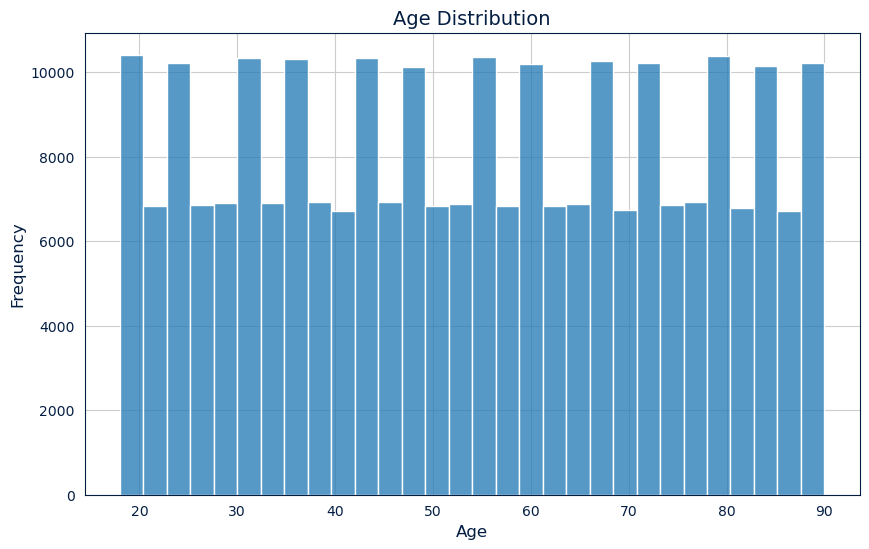

In [20]:
# Plot distribution of Age
plt.figure(figsize=(10, 6))
sns.histplot(llm_good['Age'], bins=30)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

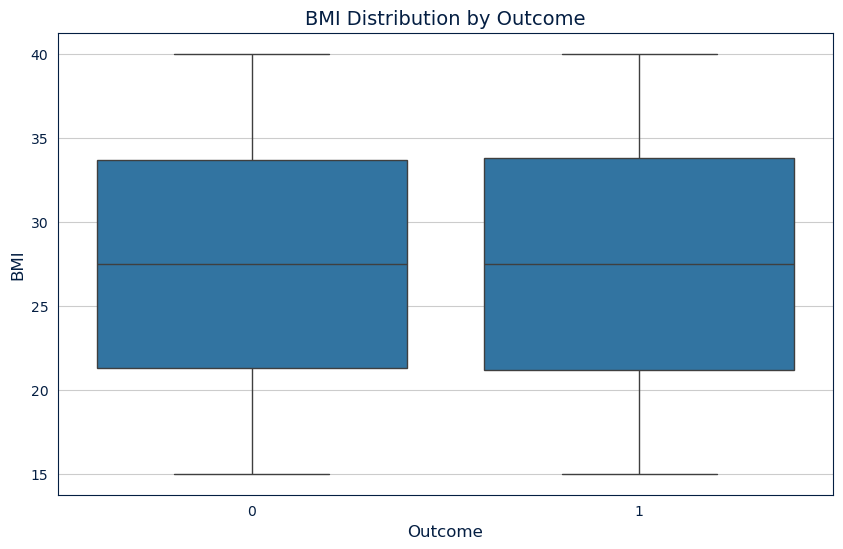

In [21]:
# Create a boxplot for BMI by Outcome
plt.figure(figsize=(10,6))
sns.boxplot(x='Outcome', y='BMI', data=llm_good)
plt.title("BMI Distribution by Outcome")
plt.xlabel("Outcome")
plt.ylabel("BMI")
plt.show()

In [22]:
# Create contingency table for Smoker vs Outcome
cont_table = pd.crosstab(llm_good['Smoker'], llm_good['Outcome'])
print(cont_table)

Outcome       0      1
Smoker                
No       108553  66326
Yes       46668  28453


<h1 style="color:#041E42; font-family:Source Sans Pro, Verdana, Arial, sans-serif;">
  <img src="https://upload.wikimedia.org/wikipedia/en/thumb/7/7a/University_of_Edinburgh_ceremonial_roundel.svg/360px-University_of_Edinburgh_ceremonial_roundel.svg.png" 
       style="vertical-align:middle; margin-right:10px; width:2em;" />
  The University of Edinburgh
</h1>

<h2 style="color:#005EB8; font-family:Source Sans Pro, Verdana, Arial, sans-serif;">MSc Data Science for Health and Social Care </h2>

<div style="border-left:6px solid #005EB8; background:#F5F9FC; padding:0.8em; border-radius:6px; margin:1em 0;">
  <b>Module:</b> Foundations of Machine Learning  

  <b>Course Organiser:</b> Mr Christopher Aldous Oldnall  
</div>

<hr style="border:none; height:4px; 
    background:linear-gradient(to right, #041E42, #005EB8, #E94B3C); 
    border-radius:2px;" />

Welcome to the first code-along for the Foundations of Machine Learning for Health and Social Care module.

In this notebook, we’ll build and compare two synthetic datasets:  
1. One generated *programmatically* using Python libraries (`numpy`, `pandas`)  
2. One generated *textually* using a Large Language Model (LLM)

You’ll learn how to create, inspect, and prepare data — and think critically about the strengths and limits of AI-generated data.

In [ ]:
# Uncomment the below if you haven't already installed the packages 
# !pip install pandas numpy matplotlib seaborn

In [ ]:
# 📦 Standard package loading.
# ==============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "axes.edgecolor": "#041E42",
    "axes.labelcolor": "#041E42",
    "xtick.color": "#041E42",
    "ytick.color": "#041E42",
    "text.color": "#041E42"
})

print("✅ Standard packages loaded and plotting style set to Edinburgh pallete")

<hr style="border:none; height:4px; 
    background:linear-gradient(to right, #041E42, #005EB8, #E94B3C); 
    border-radius:2px;" />

## 1. Generating it "the old fashioned" way.

When we generate any sort of synthetic data, we want to be able to make it replicatable. This means that someone else should be able to take our code and make the exact same data. As we have looked at briefly so far; this is super important for a multitude of reasons including; transparency in decision making processes of how to generate the data, accountability of who made the code, explanation of encoding decisions.

The best way, and one we will see throughout the course, to reduce stochasticity in our data (random-ness), is to set a "seed". You may have seen a seed before in code. This essentially says, "use the same randomness each time".

In [ ]:
# Set a random seed for reproducibility


Next we set the size of our data. Synthetic data is very useful at seeing what happens when we have large samples and we are confident we can replicate 'rough' behaviour of the true population.

In [ ]:
# Define dataset size of 250,000


Now comes the part which is a little new perhaps to you. The use of the random functions in the numpy package. Below we will see the use of three different subfunctions...

```randint(a, b, size)```: As the name suggests this will generate a random integer (whole number) between the given values a and b. It will generate `size` of these.

 ```choice([set], p=[prob_set], size)```: This makes a random choice between some given options `[set]`. We can give it an option `p` which is a set corresponding to the probabilities we want to weight of picking a certain option `[prob_set]`. The probabilities given match up to each element in the `[set]`. If we give it no `p` options will be equally weighted. Again we can set `size` to generate a specified number of values.
 
 *important note: probabilities must sum up to 1*
 
```normal(mean, standard_deviation, size)```: This picks randomly from the normal distribution (the bell-shaped curve distribution). For this we have to specify the mean and the standard deviation of the distribution. We also can specify how many values to generate via `size` once again.


In [ ]:
# Create an age variable between 18 and 90, sex variable (Male, Female), BMI variable (mean 27, std 5), smoker status (Yes, No), length of hospital stay (1 to 14 days), and complications status (None, Minor, Major).


As we will learn about in the upcoming weeks, it is important to have an specified outcome in your data. Often this might be some type of score. For our synthetic data, we will come up with a `risk_score` which decides those with higher BMI, that smoke, and have a longer stay in hospital have an increased risk (slightly).

In [ ]:
# Create risk score based on age, BMI, and smoker status.


Here we introduce the function ```where(condition, if_condition_is_true, if_condition_is_false)```. For the smoking behaviour we want to add 5 to the risk score, but nothing if they are not. Therefore here we have ```np.where(smoker == 'Yes', 5, 0)```

*important note: you may have seen `+=` in previous courses. This is syntactic sugar for `risk_score = risk_score + something_new` and should only be interpreted as Python shorthand*

In [ ]:
# Shift the risk score to be 5 higher for those who Smoke.


Over the upcoming weeks we will also learn the difference between having continious (a spectrum of numbers) and categorical outcomes (yes/no, 0/1). For our synthetic data we will create a categorical outcome which is 1 when the risk-score is above a certain value, and 0 if isn't. For this value we introduce an additional function from the `random` suite:

`rand`: This picks a random number between 0 and 1. 

Therefore what we do here, is pick a number between 0 and 1, check each risk probability and if it above this value we give it a 1 (the risk group) otherwise a 0 (the no-risk group). In reality when generating synthetic data we may seek expert advice, either directly or through existing literature, given the task we have

In [ ]:
risk_prob = 1 / (1 + np.exp(-0.1 * (risk_score - 10)))  # logistic transform
# Transform risk score into binary outcome


In [ ]:
# Combine all variables into a DataFrame


In [ ]:
# Save the synthetic dataset to a CSV file


<hr style="border:none; height:4px; 
    background:linear-gradient(to right, #041E42, #005EB8, #E94B3C); 
    border-radius:2px;" />

## 2. Generating data with an LLM

It has become more and more common to generate synthetic data using an LLM. There are advantages and disadvantages to using an LLM over more bespoke explicit coding like in Part 1. 

We can firstly go ahead and use a 'bad' prompt, and see what comes out.

"Generate a realistic synthetic healthcare dataset for teaching. Include patient demographics, health characteristics, and outcomes. Make the data look plausible and varied. Return the result as a csv table."

In [ ]:
# Load in the 'bad' LLM data.


Let's inspect what this looks like...what seems to be the problem?

In [ ]:
# Inspect the first few rows of the datasets.


Now let's go ahead and use a 'good' prompt.

"Generate a synthetic healthcare dataset with 250,000 rows.
Provide only a CSV to download, with a header row.

Columns and constraints:
- Age: integer, 18–90
- Sex: Male/Female, roughly balanced
- BMI: numeric (1 d.p.), 15–40
- Smoker: Yes/No (~30% Yes)
- Length_of_stay: integer days, 1–21, right-skewed
- Complications: None/Minor/Major, Major rare, some NA allowed
- Outcome: 0/1, adverse outcome more likely with age, complications, longer stay

No explanation. No markdown."

In [ ]:
# Load the data again to confirm it's saved correctly and invesitgate the types.


In [ ]:
# Plot distribution of Age


In [ ]:
# Create a boxplot for BMI by Outcome


In [ ]:
# Create contingency table for Smoker vs Outcome
